# Theseus: cohort financial analytics
## API introduction and end-to-end walkthrough

This is the starting point for Theseus V1. It introduces the DataFrame schemas, the core forecasting operations, the immutable result object, and the analysis and visualization APIs before routing into applied CFO and CMO scenario-planning labs.

Theseus is a library, not an application or data platform. Its inputs and outputs are **pandas DataFrames**; callers decide where data comes from and where results are stored.

### Mental model

`source DataFrames → tg.forecast(...) → ForecastResult → timeline / metrics / plots / revisions`

A cohort places an age-indexed curve on a shared timeline. `forecast` broadcasts many cohorts, overlays authoritative observations, attaches acquisition spend, and returns the canonical state needed for reporting and incremental updates.

### API at a glance

| API | Purpose |
| --- | --- |
| `tg.broadcast(...)` | Project one cohort, or a slice of one cohort, onto the timeline |
| `tg.forecast(...)` | Build a multi-cohort forecast from canonical DataFrames |
| `result.contributions` | Inspect the resolved long-form cohort ledger |
| `result.timeline()` / `result.metrics()` | Calculate revenue, contribution, marketing P&L, LTV, ROAS, break-even, and cash at risk |
| `result.advance(...)` | Move the cursor forward one daily period with new cohorts, observations, or spend |
| `result.broadcast(...)` | Revise selected modeled cohorts while preserving observations |
| `result.plot...` / `tg.viz...` | Build chart-ready financial and cohort views |
| `tg.io...` | Load or validate CSV, XLSX, and read-only database sources |

### Walkthrough map

1. Learn the atomic broadcast and canonical schemas.
2. Construct a forecast and overlay observations.
3. Inspect the contribution ledger, financial timeline, metrics, and visualizations.
4. Advance the model, revise assumptions, compare scenarios, and use calendar timelines.
5. Load external DataFrames and export results.

The examples use **deterministic synthetic data**, not measured channel benchmarks. Facebook and Google are illustrative labels carried over from the original notebook.

### Applied scenario-planning labs

After this API walkthrough, continue with the role-specific notebooks:

- [Game CFO: growth, liquidity, and a $1MM cash target](examples/notebooks/Game_CFO_Cash_Flow_Optimization.ipynb)
- [Subscription CFO: channel experiments, scaling, and the CTV halo](examples/notebooks/Subscription_CFO_Channel_Experiments.ipynb)
- [Subscription CMO: Waterfall and Distributed campaign budgeting](examples/notebooks/Subscription_CMO_Campaign_Optimization.ipynb)

### Related Mobile Dev Memo reading

- [Building a marketing P&L using LTV and ROAS](https://mobiledevmemo.com/ltv-roas-marketing-p-and-l/)
- [Optimization models in digital advertising](https://mobiledevmemo.com/optimization-models-in-digital-advertising/)

### Run this notebook

Use Python 3.10 or newer. From the repository root, install the checkout into your chosen environment:

```bash
python -m pip install -e ".[viz,excel]" jupyterlab ipykernel
python -m jupyter lab Theseus_Walkthrough.ipynb
```

Select that environment's Python kernel, then **Restart Kernel and Run All Cells**. The notebook needs no downloads, credentials, or external data after installation. Cells near the end write demo exports under `examples/output/notebook/`; rerunning replaces only those named demo files.

In [1]:
from pathlib import Path
from contextlib import closing
import sqlite3

import numpy as np
import pandas as pd
from pandas.testing import assert_frame_equal
from IPython.display import display
from matplotlib.figure import Figure

import theseus_growth as tg

%matplotlib inline

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 12)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

print(f"Theseus {tg.__version__} | pandas {pd.__version__}")

Theseus 1.0.0 | pandas 3.0.6


## 1. Atomic projection: `tg.broadcast`

A curve is age-indexed; a cohort places it on a shared timeline. **Age zero is the acquisition period.** Integer periods are abstract daily steps, not Unix timestamps.

Suppose cumulative revenue per original user is $0.50, $0.80, and $1.00 after the first three days. Forecasting needs the incremental values: $0.50, $0.30, and $0.20. No retention model is required when you already have direct monetization curves.

In [2]:
cumulative_curve = pd.DataFrame({
    "curve_id": ["simple"] * 3,
    "age": [0, 1, 2],
    "component": ["revenue"] * 3,
    "category": ["revenue"] * 3,
    "value": [0.50, 0.80, 1.00],
})
incremental_curve = tg.cumulative_to_incremental(cumulative_curve)

one_cohort = {
    "cohort_id": "demo",
    "acquisition_period": 2,
    "population": 100,
    "curve_id": "simple",
}
one_broadcast = tg.broadcast(one_cohort, incremental_curve, start=2, end=4)
display(incremental_curve[["age", "value"]])
display(one_broadcast[["cohort_id", "period", "age", "amount", "basis"]])

np.testing.assert_allclose(one_broadcast["amount"], [50, 30, 20])
assert one_broadcast["period"].tolist() == [2, 3, 4]

,age,value
0,0,0.5000
1,1,0.3000
2,2,0.2000


,cohort_id,period,age,amount,basis
0,demo,2,0,50.0000,projected
1,demo,3,1,30.0000,projected
2,demo,4,2,20.0000,projected


In [3]:
# Broadcasting is also the same atomic operation for a portion of a timeline.
broadcast_slice = tg.broadcast(one_cohort, incremental_curve, start=3, end=4)
assert_frame_equal(
    broadcast_slice.reset_index(drop=True),
    one_broadcast.loc[one_broadcast["period"].between(3, 4)].reset_index(drop=True),
)
display(broadcast_slice[["period", "age", "amount"]])

,period,age,amount
0,3,1,30.0000
1,4,2,20.0000


## 2. Canonical schemas: cohorts, curves, and acquisition spend

Now separate retention from per-active-user economics. This lets a retention-only revision change projected revenue and variable costs later.

For each age:

`active users = original population × retention`

`revenue = active users × (IAP revenue per active user + ad revenue per active user)`

`contribution = revenue − variable costs`

Retention uses proportions between 0 and 1, not percentages. Activity rows do not enter financial totals; cost inputs are positive amounts and enter P&L negatively. Acquisition spend is separate from variable costs.

We supply a dense row for **every age and component**. V1 does not fit or extrapolate sparse curves automatically. A known zero needs an explicit zero row.

In [4]:
AS_OF = 28
FORECAST_END = 119  # Inclusive: 120 daily periods starting at zero.
AGES = np.arange(FORECAST_END + 2)  # One extra age for a rolling-horizon advance.

channel_specs = {
    "facebook": {
        "population": 1000, "cpi": 1.15,
        "retention_floor": 0.04, "retention_decay": 12,
        "iap": 0.090, "ads": 0.030, "variable_cost": 0.008,
    },
    "google": {
        "population": 800, "cpi": 1.30,
        "retention_floor": 0.035, "retention_decay": 18,
        "iap": 0.080, "ads": 0.025, "variable_cost": 0.010,
    },
}

curve_parts = []
for channel, spec in channel_specs.items():
    retention = spec["retention_floor"] + (
        1 - spec["retention_floor"]
    ) * np.exp(-AGES / spec["retention_decay"])
    curve_parts.append(pd.DataFrame({
        "curve_id": channel, "age": AGES,
        "component": "retention", "category": "activity",
        "value": retention, "value_basis": "per_original_user",
        "curve_version": 1,
    }))
    for component, category in [
        ("iap", "revenue"), ("ads", "revenue"), ("variable_cost", "cost")
    ]:
        curve_parts.append(pd.DataFrame({
            "curve_id": channel, "age": AGES,
            "component": component, "category": category,
            "value": spec[component], "value_basis": "per_active_user",
            "driver_component": "retention", "curve_version": 1,
        }))

curves = pd.concat(curve_parts, ignore_index=True)
display(curves.groupby(["curve_id", "component", "category", "value_basis"]).agg(
    ages=("age", "count"), first_value=("value", "first")
).reset_index())

,curve_id,component,category,value_basis,ages,first_value
0,facebook,ads,revenue,per_active_user,121,0.0300
1,facebook,iap,revenue,per_active_user,121,0.0900
2,facebook,retention,activity,per_original_user,121,1.0000
3,facebook,variable_cost,cost,per_active_user,121,0.0080
4,google,ads,revenue,per_active_user,121,0.0250
5,google,iap,revenue,per_active_user,121,0.0800
6,google,retention,activity,per_original_user,121,1.0000
7,google,variable_cost,cost,per_active_user,121,0.0100


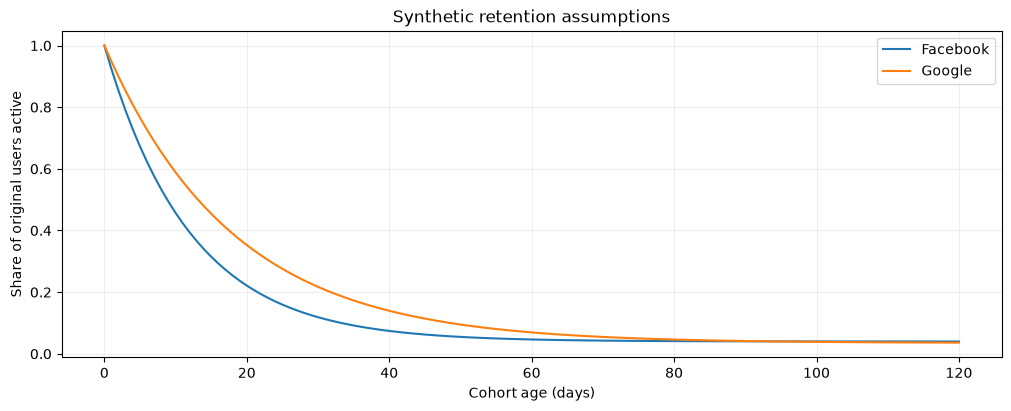

In [5]:
# Like the original notebook, inspect retention before projecting populations.
retention_figure = Figure(figsize=(10, 4), layout="constrained")
retention_ax = retention_figure.subplots()
for channel in channel_specs:
    profile = curves.loc[
        curves["curve_id"].eq(channel) & curves["component"].eq("retention")
    ]
    retention_ax.plot(profile["age"], profile["value"], label=channel.title())
retention_ax.set(
    title="Synthetic retention assumptions",
    xlabel="Cohort age (days)", ylabel="Share of original users active",
)
retention_ax.legend()
retention_ax.grid(alpha=0.2)
display(retention_figure)

In [6]:
def make_acquisitions(periods):
    """Demo data generator, not a Theseus requirement."""
    cohort_rows, spend_rows = [], []
    for period in periods:
        for channel, spec in channel_specs.items():
            cohort_id = f"{channel}-{period:03d}"
            cohort_rows.append({
                "cohort_id": cohort_id,
                "acquisition_period": period,
                "population": spec["population"],
                "curve_id": channel,
                "channel": channel,
            })
            spend_rows.append({
                "cohort_id": cohort_id,
                "period": period,
                "amount": spec["population"] * spec["cpi"],
            })
    return pd.DataFrame(cohort_rows), pd.DataFrame(spend_rows)


cohorts, acquisition_spend = make_acquisitions([0, 7, 14, 21])
display(cohorts)
display(acquisition_spend)

# Explicit cohort IDs on spend avoid ambiguous allocation:
# two channels acquire users on each of the same four days.
baseline = tg.forecast(
    cohorts, curves,
    acquisition_spend=acquisition_spend,
    as_of=AS_OF,
    forecast_end=FORECAST_END,
)
display(baseline.contributions[
    ["cohort_id", "period", "age", "component", "amount", "pnl_amount", "basis"]
].head(8))

,cohort_id,acquisition_period,population,curve_id,channel
0,facebook-000,0,1000,facebook,facebook
1,google-000,0,800,google,google
2,facebook-007,7,1000,facebook,facebook
3,google-007,7,800,google,google
4,facebook-014,14,1000,facebook,facebook
5,google-014,14,800,google,google
6,facebook-021,21,1000,facebook,facebook
7,google-021,21,800,google,google


,cohort_id,period,amount
0,facebook-000,0,"1,150.0000"
1,google-000,0,"1,040.0000"
2,facebook-007,7,"1,150.0000"
3,google-007,7,"1,040.0000"
4,facebook-014,14,"1,150.0000"
5,google-014,14,"1,040.0000"
6,facebook-021,21,"1,150.0000"
7,google-021,21,"1,040.0000"


,cohort_id,period,age,component,amount,pnl_amount,basis
0,facebook-000,0,0,ads,30.0000,30.0000,projected
1,facebook-000,0,0,iap,90.0000,90.0000,projected
2,facebook-000,0,0,retention,"1,000.0000",0.0000,projected
3,facebook-000,0,0,variable_cost,8.0000,-8.0000,projected
4,google-000,0,0,ads,20.0000,20.0000,projected
5,google-000,0,0,iap,64.0000,64.0000,projected
6,google-000,0,0,retention,800.0000,0.0000,projected
7,google-000,0,0,variable_cost,8.0000,-8.0000,projected


## 3. Forecast construction and observation overlay: `tg.forecast`

In production, observations come from your measurement process. Here we synthesize a daily feed from the baseline and apply a small deterministic revenue variation, solely to keep the tutorial self-contained.

Observation `amount` is a **cohort total**, not a per-user value. A row replaces the projection with the same `(cohort_id, period, component)`. Missing observations stay modeled; passing `as_of` does **not** turn modeled history into actuals. Observed activity does not automatically refit retention or recompute other components: supply their observed totals separately.

In [7]:
def demo_observations(projected_rows):
    """Synthetic feed; replace this function with your measured DataFrame."""
    observed = projected_rows[
        ["cohort_id", "period", "component", "category", "amount"]
    ].copy()
    is_revenue = observed["category"].eq("revenue")
    variation = 0.97 + 0.04 * np.sin(
        projected_rows.loc[is_revenue, "period"].to_numpy() * 0.18
        + projected_rows.loc[is_revenue, "age"].to_numpy() * 0.10
    )
    observed.loc[is_revenue, "amount"] *= variation
    return observed.reset_index(drop=True)


observations = demo_observations(
    baseline.projections.loc[baseline.projections["period"].le(AS_OF)]
)
source_frames = tg.SourceFrames(
    cohorts=cohorts,
    curves=curves,
    observations=observations,
    acquisition_spend=acquisition_spend,
)
result = tg.forecast(
    source_frames, as_of=AS_OF, forecast_end=FORECAST_END
)
ledger = result.contributions
display(ledger.groupby(["category", "basis"])["amount"].agg(["count", "sum"]))
assert ledger.loc[ledger["period"].le(AS_OF), "basis"].eq("observed").all()

count         sum
category basis                       
activity observed     148 75,177.1010
         projected    728 59,626.4928
cost     observed     148    674.9882
         projected    728    541.9673
revenue  observed     296  8,187.2572
         projected   1456  6,668.0141

In [8]:
keys = ["cohort_id", "period", "component"]
resolved_actuals = ledger.loc[ledger["basis"].eq("observed")].set_index(keys)
input_actuals = observations.set_index(keys)
np.testing.assert_allclose(
    resolved_actuals["amount"].sort_index(),
    input_actuals["amount"].sort_index(),
)

# Keep rows inspectable: assumptions, effective per-user values, totals, and basis.
display(ledger.loc[
    ledger["cohort_id"].eq("facebook-000")
    & ledger["component"].eq("iap")
    & ledger["period"].between(AS_OF - 1, AS_OF + 2),
    ["period", "source_value", "value_per_user", "amount", "basis"],
])

,period,source_value,value_per_user,amount,basis
529,27,0.0900,0.0128,12.8118,observed
561,28,0.0900,0.0121,12.0981,observed
593,29,0.0900,0.0113,11.3085,projected
625,30,0.0900,0.0107,10.6921,projected


## 4. Financial outputs: `contributions`, `timeline`, and `metrics`

`timeline()` aggregates the resolved ledger. `marketing_pnl()` is an alias.

- Revenue excludes costs and activity.
- Contribution subtracts variable costs; marketing P&L also subtracts acquisition spend.
- Portfolio **LTV** here is contribution per original user; **ROAS** is revenue divided by acquisition spend.
- “Lifetime” values stop at `forecast_end`; they are not infinite-horizon estimates.
- `metrics().projected_receivable` is future **net contribution**. The visualization suite's receivables are future **revenue** from already-acquired cohorts. Do not treat the two as interchangeable.

`is_actual_period` in the timeline means the period is at or before the cursor, not that every component has been observed. Capital at risk assumes same-period settlement, not payment delays.

In [9]:
timeline = result.timeline()
display(timeline.loc[
    timeline["period"].isin([0, 7, AS_OF, AS_OF + 1, FORECAST_END]),
    ["period", "recorded_revenue", "projected_revenue", "cost",
     "acquisition_spend", "marketing_pnl", "cumulative_marketing_pnl"],
])
display(result.metrics().T.rename(columns={0: "value"}))

np.testing.assert_allclose(
    timeline["marketing_pnl"],
    timeline["revenue"] - timeline["cost"] - timeline["acquisition_spend"],
)
assert_frame_equal(timeline, result.marketing_pnl())

,period,recorded_revenue,projected_revenue,cost,acquisition_spend,marketing_pnl,cumulative_marketing_pnl
0,0,197.8800,0.0000,16.0000,"2,190.0000","-2,008.1200","-2,008.1200"
7,7,333.5078,0.0000,26.1184,"2,190.0000","-1,882.6106","-2,998.7421"
28,28,288.8630,0.0000,23.9696,0.0000,264.8934,"-1,247.7309"
29,29,0.0000,279.0729,22.5770,0.0000,256.4958,-991.2351
119,119,0.0000,31.8843,2.4861,0.0000,29.3982,"4,878.3159"


,value
cursor,28.0000
forecast_end,119.0000
recorded_contribution,"7,512.2691"
projected_receivable,"6,126.0469"
lifetime_contribution,"13,638.3159"
acquisition_spend,"8,760.0000"
marketing_pnl,"4,878.3159"
ltv,1.8942
roas,1.6958
break_even_period,34.0000


### Slice by channel or cohort age with pandas

Additional cohort dimensions survive on ledger rows. There is no separate reporting schema to learn. This also replaces the original notebook's channel-combination and aged-user examples.

In [10]:
channel_financials = ledger.loc[ledger["category"].ne("activity")].groupby(
    "channel"
)["pnl_amount"].sum().rename("contribution")
channel_spend = acquisition_spend.merge(
    cohorts[["cohort_id", "channel"]], on="cohort_id", validate="many_to_one"
).groupby("channel")["amount"].sum()
channel_summary = pd.concat(
    [channel_financials, channel_spend.rename("acquisition_spend")], axis=1
)
channel_summary["marketing_pnl"] = (
    channel_summary["contribution"] - channel_summary["acquisition_spend"]
)
display(channel_summary)

active_users = ledger.loc[ledger["component"].eq("retention")].copy()
active_users["age_band"] = pd.cut(
    active_users["age"], bins=[-1, 6, 29, np.inf],
    labels=["0–6 days", "7–29 days", "30+ days"],
)
active_by_age = active_users.pivot_table(
    index="period", columns="age_band", values="amount",
    aggfunc="sum", observed=False, fill_value=0,
)
display(active_by_age.loc[[0, 7, AS_OF, 60, FORECAST_END]])

,contribution,acquisition_spend,marketing_pnl
channel,,,
facebook,"7,188.8691","4,600.0000","2,588.8691"
google,"6,449.4468","4,160.0000","2,289.4468"


age_band,0–6 days,7–29 days,30+ days
period,,,
0,"1,800.0000",0.0000,0.0000
7,"1,800.0000","1,126.9827",0.0000
28,0.0000,"2,647.8736",0.0000
60,0.0000,0.0000,564.6112
119,0.0000,0.0000,280.7237


## 5. Visualization API: `result.plot` and `tg.viz`

Each chart returns a `Chart`: `figure`, `ax`, the exact underlying `data` DataFrame, and sometimes extra `tables`. Nothing is displayed automatically; use `display(chart.figure)` in a notebook.

The figures below move from per-user monetization to the portfolio marketing P&L. They use the notebook's synthetic data; they do not reproduce an external article's dataset. Solid cohort-curve segments are observed; dashed segments include projections.

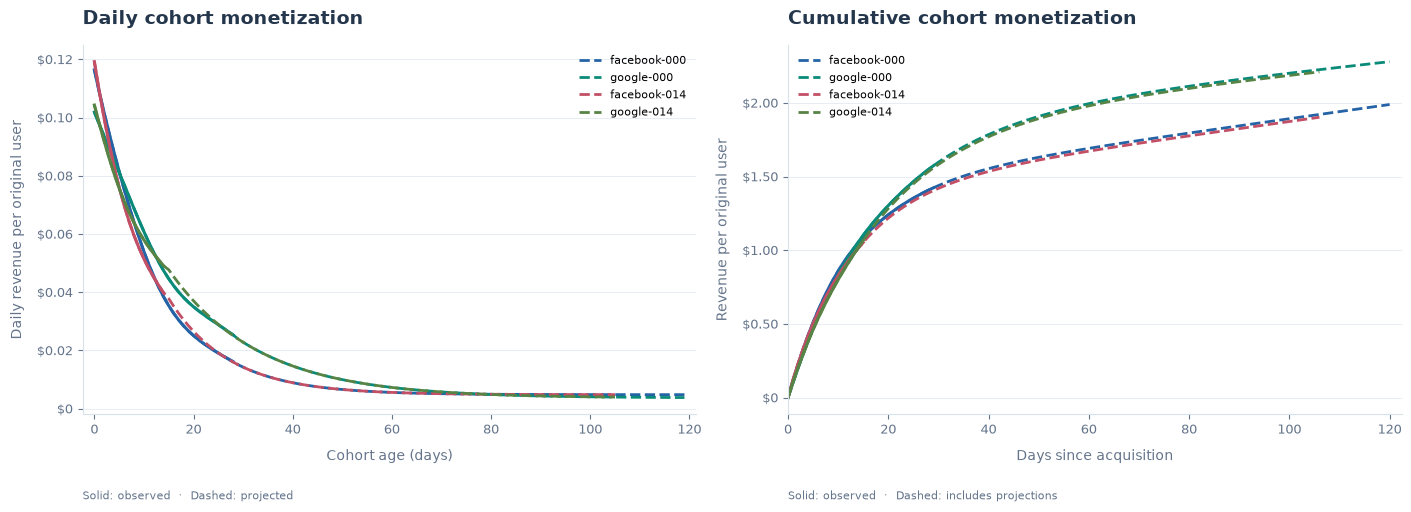

,cohort_id,acquisition_period,period,age,elapsed_days,revenue,...,population,complete,value_status,cumulative_status,revenue_per_user,cumulative_revenue_per_user
0,facebook-000,0,0,0,1,116.4000,...,"1,000.0000",True,observed,observed,0.1164,0.1164
1,facebook-000,0,1,1,2,108.6901,...,"1,000.0000",True,observed,observed,0.1087,0.2251
2,facebook-000,0,2,2,3,101.4192,...,"1,000.0000",True,observed,observed,0.1014,0.3265
3,facebook-000,0,3,3,4,94.4976,...,"1,000.0000",True,observed,observed,0.0945,0.4210


In [11]:
selected_cohorts = ["facebook-000", "google-000", "facebook-014", "google-014"]

# Every individual chart accepts an existing Matplotlib Axes.
monetization_figure = Figure(figsize=(14, 5), layout="constrained")
monetization_axes = monetization_figure.subplots(1, 2)
daily_chart = result.plot.daily_monetization(
    cohorts=selected_cohorts, ax=monetization_axes[0]
)
cumulative_chart = result.plot.cumulative_monetization(
    cohorts=selected_cohorts, ax=monetization_axes[1]
)
display(monetization_figure)
display(cumulative_chart.data.head(4))

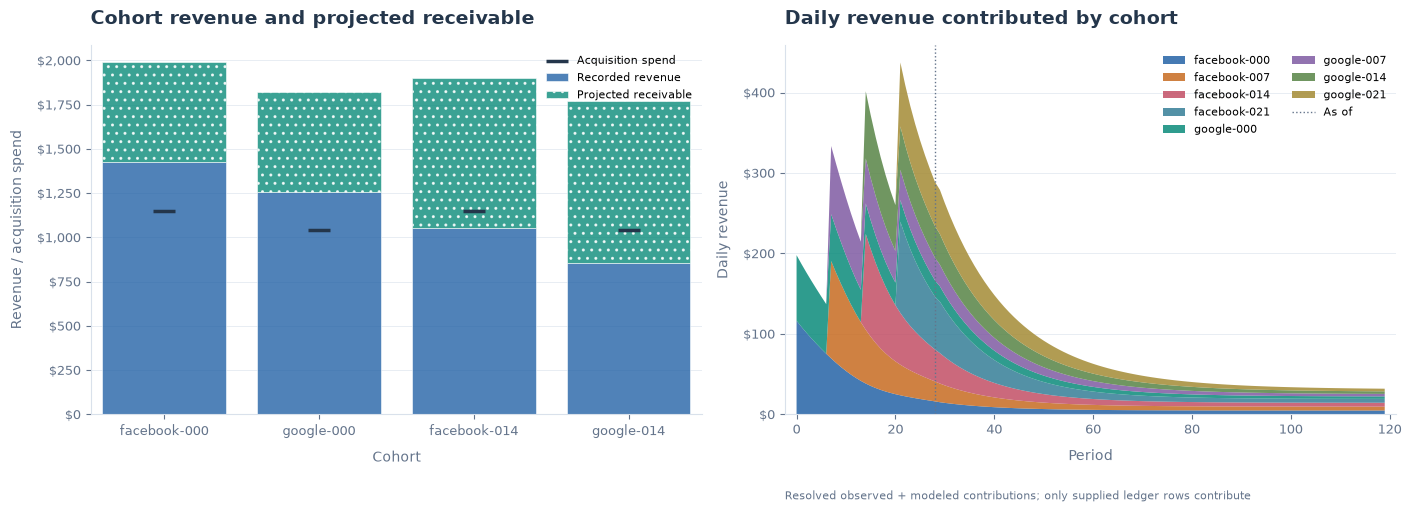

,cohort_id,recorded_revenue,projected_receivable,expected_revenue,acquisition_spend,expected_roas
0,facebook-000,"1,423.4520",565.2806,"1,988.7326","1,150.0000",1.7293
1,google-000,"1,258.5529",565.1266,"1,823.6795","1,040.0000",1.7535
2,facebook-007,"1,285.5878",667.0375,"1,952.6253","1,150.0000",1.6979
3,google-007,"1,093.7258",706.5816,"1,800.3073","1,040.0000",1.7311
4,facebook-014,"1,052.9005",849.3860,"1,902.2865","1,150.0000",1.6542
5,google-014,852.9001,915.2759,"1,768.1759","1,040.0000",1.7002
6,facebook-021,693.3918,"1,176.1549","1,869.5467","1,150.0000",1.6257
7,google-021,526.7464,"1,223.1710","1,749.9174","1,040.0000",1.6826


In [12]:
revenue_figure = Figure(figsize=(14, 5), layout="constrained")
revenue_axes = revenue_figure.subplots(1, 2)
recorded_chart = result.plot.recorded_vs_projected(
    cohorts=selected_cohorts, ax=revenue_axes[0]
)
stacked_chart = result.plot.cohort_revenue(ax=revenue_axes[1])
display(revenue_figure)

cohort_summary = tg.viz.cohort_summary_data(result)
display(cohort_summary[
    ["cohort_id", "recorded_revenue", "projected_receivable",
     "expected_revenue", "acquisition_spend", "expected_roas"]
])

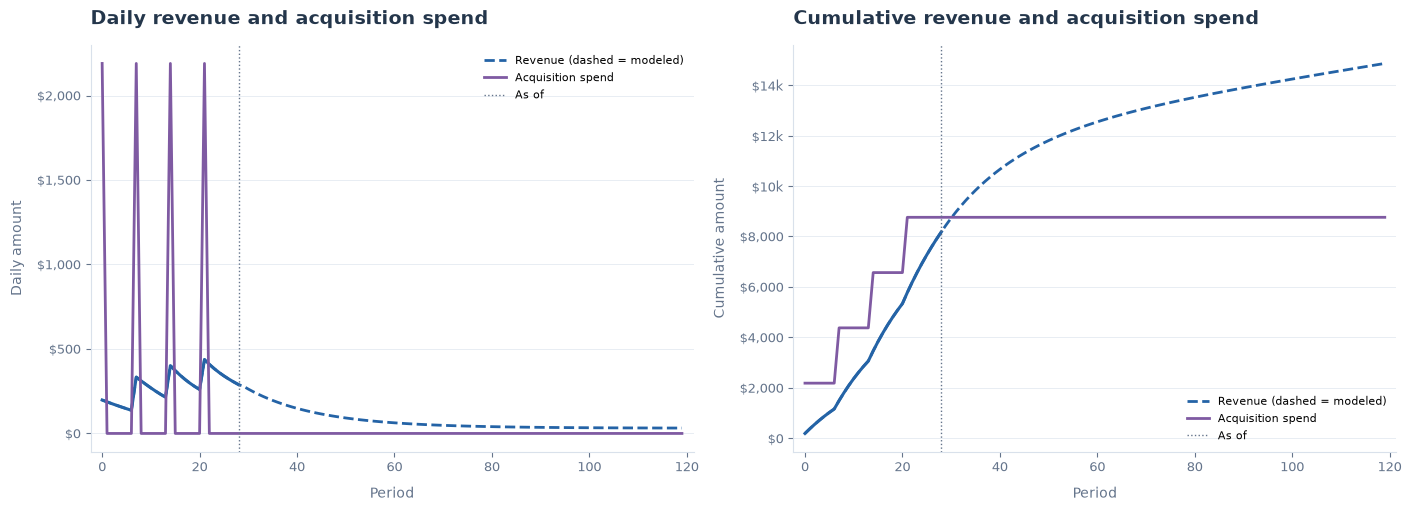

In [13]:
spend_figure = Figure(figsize=(14, 5), layout="constrained")
spend_axes = spend_figure.subplots(1, 2)
result.plot.revenue_vs_spend(ax=spend_axes[0])
result.plot.cumulative_revenue_vs_spend(ax=spend_axes[1])
display(spend_figure)

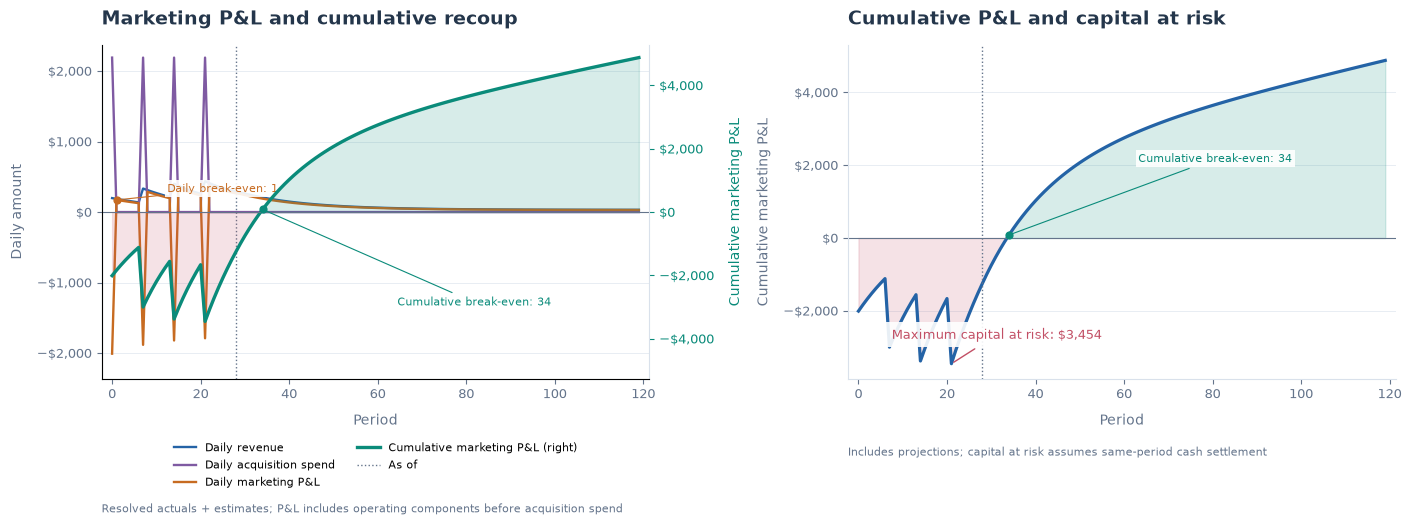

,event,period
0,daily_break_even,1
1,cumulative_break_even,34
2,maximum_capital_at_risk,21


In [14]:
pnl_figure = Figure(figsize=(14, 5), layout="constrained")
pnl_axes = pnl_figure.subplots(1, 2)
pnl_chart = result.plot.marketing_pnl(ax=pnl_axes[0])
risk_chart = result.plot.cumulative_pnl(ax=pnl_axes[1])
display(pnl_figure)
display(tg.viz.break_even_data(result))

The remaining-receivables series below recalculates how much future revenue remains, within the fixed horizon, from cohorts acquired by each point. It uses the **current assumption/observation snapshot**; it is not a history of what the model predicted on each previous day. Break-even annotations mark a first crossing, not a promise that P&L stays positive thereafter.

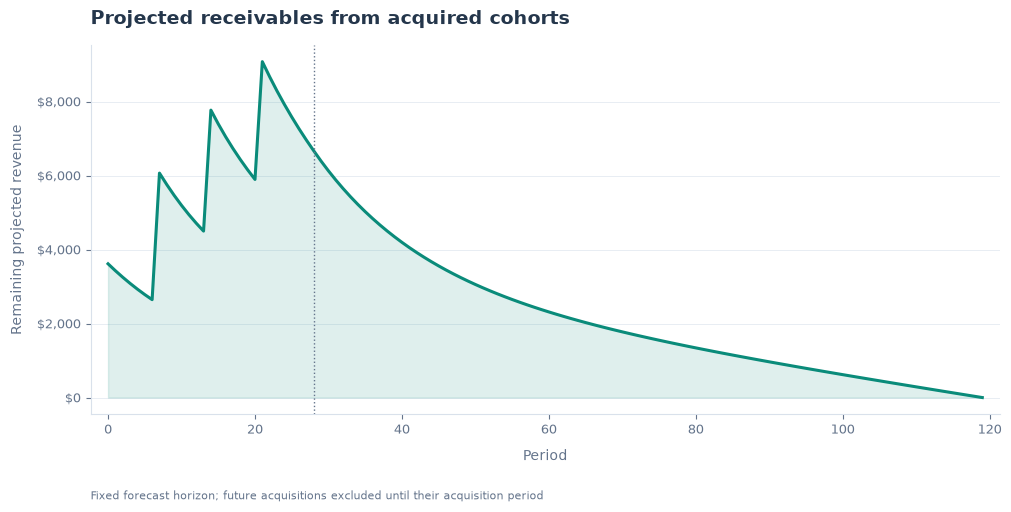

,period,recorded_revenue,modeled_revenue_to_date,projected_receivable
0,0,197.8800,0.0000,"3,614.5321"
1,1,384.6812,0.0000,"3,427.7310"
2,2,560.9154,0.0000,"3,251.4967"
3,3,726.9535,0.0000,"3,085.4586"


In [15]:
receivables_chart = result.plot.projected_receivables()
display(receivables_chart.figure)
display(receivables_chart.data.head(4))

## 6. Cohort analytics: origin-aligned ROAS progression

Each cohort starts at `(0, 0)`, immediately before revenue accrues. Subsequent points show **cumulative cohort revenue ÷ that cohort's acquisition spend**.

- Daily checkpoint 1 includes age-zero revenue.
- Weekly checkpoint 1 includes ages 0–6; checkpoint 2 includes ages 0–13.
- `interval` changes age checkpoints, **not** the grouping of acquisition cohorts.
- `basis="resolved"` combines actuals and projections; `"observed"` stops at the cursor and requires observed revenue; `"projected"` uses modeled rows.
- Younger cohorts stop earlier. Unknown ages are not zero-padded; missing revenue propagates to unknown cumulative ROAS.
- No positive cohort spend means undefined ROAS, not zero.

Use `result.cohort_progression(...)` for the chart-ready DataFrame without rendering or requiring Matplotlib.

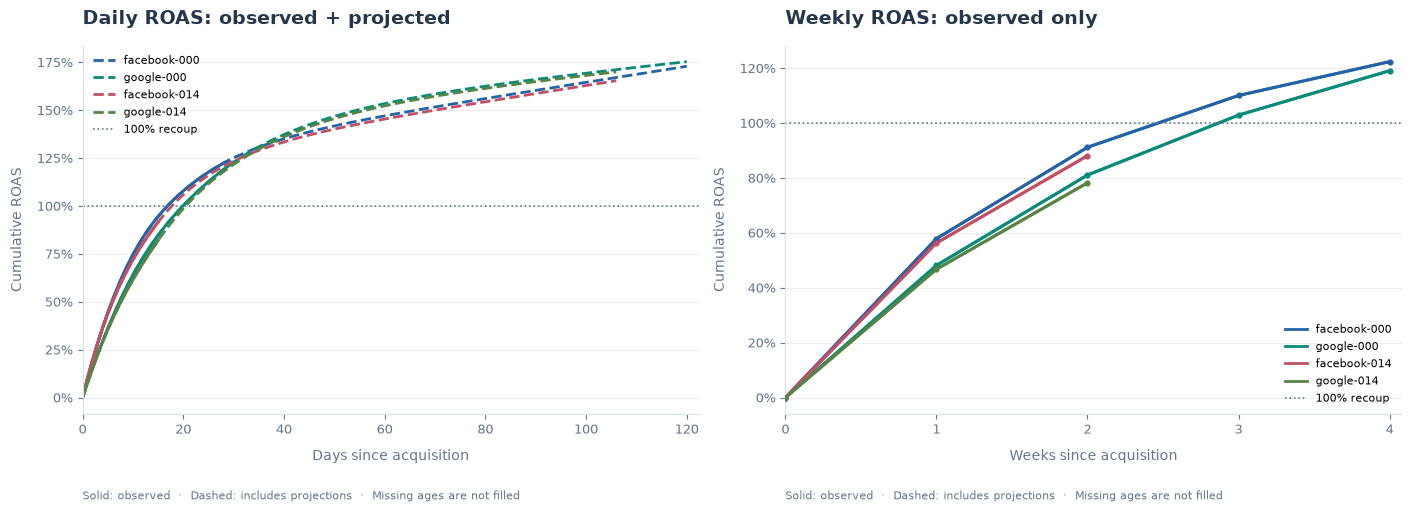

,cohort_id,interval_index,elapsed_days,cumulative_revenue,acquisition_spend,roas,value_status
0,facebook-000,0,0,0.0000,"1,150.0000",0.0000,origin
1,facebook-000,1,7,665.7820,"1,150.0000",0.5789,observed
2,facebook-000,2,14,"1,048.6172","1,150.0000",0.9118,observed
3,facebook-000,3,21,"1,265.6591","1,150.0000",1.1006,observed
4,facebook-000,4,28,"1,407.3212","1,150.0000",1.2238,observed
...,...,...,...,...,...,...,...
11,facebook-014,1,7,647.4427,"1,150.0000",0.5630,observed
12,facebook-014,2,14,"1,013.1929","1,150.0000",0.8810,observed
13,google-014,0,0,0.0000,"1,040.0000",0.0000,origin
14,google-014,1,7,486.1024,"1,040.0000",0.4674,observed


In [16]:
progression_figure = Figure(figsize=(14, 5), layout="constrained")
progression_axes = progression_figure.subplots(1, 2)
daily_progression_chart = result.plot.cohort_progression(
    interval="daily", cohorts=selected_cohorts, ax=progression_axes[0],
    title="Daily ROAS: observed + projected",
)
weekly_progression_chart = result.plot.cohort_progression(
    interval="weekly", cohorts=selected_cohorts, basis="observed",
    ax=progression_axes[1], title="Weekly ROAS: observed only",
)
display(progression_figure)

weekly_progression = result.cohort_progression(
    interval="weekly", cohorts=selected_cohorts, basis="observed"
)
display(weekly_progression[
    ["cohort_id", "interval_index", "elapsed_days",
     "cumulative_revenue", "acquisition_spend", "roas", "value_status"]
])
assert weekly_progression.loc[weekly_progression["is_origin"], "roas"].eq(0).all()

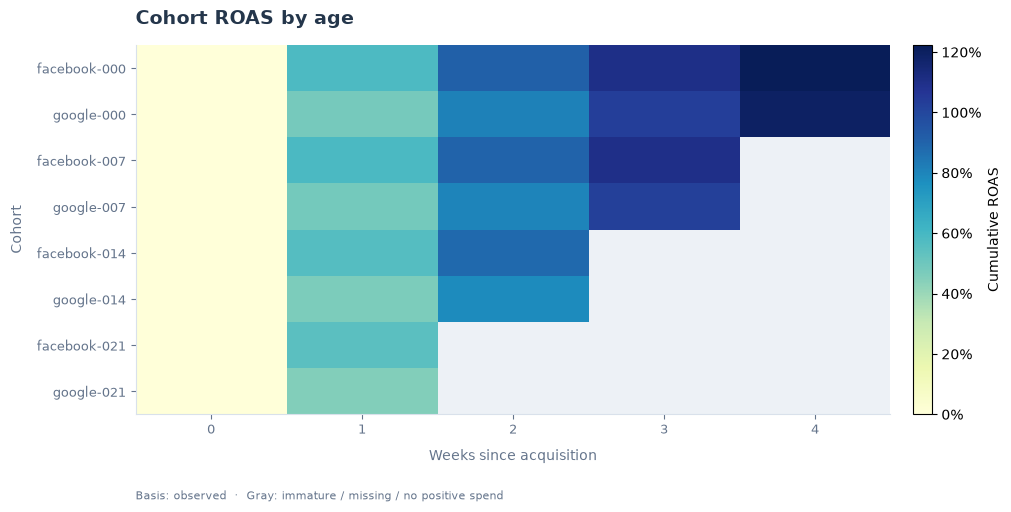

interval_index,0,1,2,3,4
cohort_id,,,,,
facebook-000,0.0000,0.5789,0.9118,1.1006,1.2238
google-000,0.0000,0.4815,0.8107,1.0290,1.1907
facebook-007,0.0000,0.5835,0.9031,1.0963,NaN
google-007,0.0000,0.4847,0.8008,1.0246,NaN
facebook-014,0.0000,0.5630,0.8810,NaN,NaN
google-014,0.0000,0.4674,0.7824,NaN,NaN
facebook-021,0.0000,0.5459,NaN,NaN,NaN
google-021,0.0000,0.4537,NaN,NaN,NaN


In [17]:
# Hand-check the first weekly point: seven daily totals, divided by cohort spend.
first_id = selected_cohorts[0]
first_week_revenue = ledger.loc[
    ledger["cohort_id"].eq(first_id)
    & ledger["category"].eq("revenue")
    & ledger["age"].between(0, 6), "amount"
].sum()
first_cohort_spend = acquisition_spend.loc[
    acquisition_spend["cohort_id"].eq(first_id), "amount"
].sum()
first_week_point = weekly_progression.loc[
    weekly_progression["cohort_id"].eq(first_id)
    & weekly_progression["interval_index"].eq(1), "roas"
].iloc[0]
np.testing.assert_allclose(first_week_point, first_week_revenue / first_cohort_spend)

heatmap_chart = result.plot.roas_heatmap(interval="weekly", basis="observed")
display(heatmap_chart.figure)
display(heatmap_chart.tables["matrix"])

## 7. Incremental state updates: `result.advance`

The cursor is at period 28. The next feed contains **only period 29**: measured contributions, new cohorts, and their acquisition spend. We generate that feed below; your application would ingest it.

`advance` returns a new result. It retains old projections and observations, overlays the new measurements, and broadcasts new cohorts. By default it also extends the horizon by one day, broadcasting only that new tail for existing cohorts. Use `extend=False` to keep a fixed horizon.

When supplied, next-day spend replaces **all** prior spend rows for that day; include the complete day's spend in that DataFrame. Omitting spend retains any existing plan. Advancing does not automatically refit curves.

In [18]:
next_period = result.cursor + 1
new_cohorts, new_spend = make_acquisitions([next_period])

# Generate synthetic observations just for the new day, not the entire history.
existing_day = result.projections.loc[
    result.projections["period"].eq(next_period)
]
new_day = pd.concat([
    tg.broadcast(
        row,
        curves.loc[curves["curve_id"].eq(row["curve_id"])],
        start=next_period, end=next_period,
    )
    for _, row in new_cohorts.iterrows()
], ignore_index=True)
next_observations = demo_observations(
    pd.concat([existing_day, new_day], ignore_index=True)
)

advanced = result.advance(
    observations=next_observations,
    cohorts=new_cohorts,
    acquisition_spend=new_spend,
)
display(pd.DataFrame([
    {"snapshot": "before", "cursor": result.cursor, "end": result.forecast_end,
     "cohorts": len(result.cohorts), "observations": len(result.observations)},
    {"snapshot": "after", "cursor": advanced.cursor, "end": advanced.forecast_end,
     "cohorts": len(advanced.cohorts), "observations": len(advanced.observations)},
]))
assert result.cursor == AS_OF
assert advanced.cursor == AS_OF + 1
assert advanced.forecast_end == FORECAST_END + 1

,snapshot,cursor,end,cohorts,observations
0,before,28,119,8,592
1,after,29,120,10,632


In [19]:
# A full rebuild is unnecessary in daily use; do it once here as a correctness check.
rebuilt = tg.forecast(
    pd.concat([cohorts, new_cohorts], ignore_index=True),
    curves,
    observations=pd.concat([observations, next_observations], ignore_index=True),
    acquisition_spend=pd.concat([acquisition_spend, new_spend], ignore_index=True),
    as_of=next_period,
    forecast_end=FORECAST_END + 1,
)

def comparable_ledger(forecast_result):
    return forecast_result.contributions.sort_values(keys).reset_index(drop=True)


assert_frame_equal(comparable_ledger(advanced), comparable_ledger(rebuilt))
assert_frame_equal(advanced.timeline(), rebuilt.timeline())
assert_frame_equal(advanced.metrics(), rebuilt.metrics())

fixed_horizon = result.advance(
    observations=next_observations,
    cohorts=new_cohorts,
    acquisition_spend=new_spend,
    extend=False,
)
assert fixed_horizon.forecast_end == FORECAST_END
print("Incremental ledger, timeline, and metrics match a full rebuild.")
display(advanced.timeline().loc[
    advanced.timeline()["period"].eq(next_period)
])

Incremental ledger, timeline, and metrics match a full rebuild.


,period,is_actual_period,recorded_revenue,projected_revenue,revenue,cost,recorded_contribution,projected_contribution,contribution_before_acquisition,acquisition_spend,marketing_pnl,cumulative_marketing_pnl
29,29,True,464.6343,0.0000,464.6343,38.5770,426.0572,0.0000,426.0572,"2,190.0000","-1,763.9428","-3,011.6737"


## 8. Scenario revisions: `result.broadcast`

Suppose new evidence suggests the first Facebook cohort retains better than assumed. Replace only its retention rows, keeping the per-active-user economics unchanged.

A full broadcast recomputes its modeled contribution from acquisition onward; a partial broadcast replaces only an inclusive timeline slice. **Observed totals remain authoritative**, and unselected cohorts stay unchanged. To restate actuals themselves, rebuild from corrected source observations; a curve revision deliberately does not overwrite them.

This is the same projection operation used at instantiation—not a special “replace curve” concept. We branch from `result` here so the before/after comparison isolates the assumption change from the new day's acquisitions.

In [20]:
revised_id = "facebook-000"
retention_patch = curves.loc[
    curves["curve_id"].eq("facebook")
    & curves["component"].eq("retention")
].copy()
retention_patch["value"] = 0.04 + 0.96 * np.exp(-retention_patch["age"] / 18)
retention_patch["curve_version"] = 2

revised = result.broadcast(
    cohorts=[revised_id],
    curves=retention_patch,
    start=0,
    end=FORECAST_END,
)

def observed_totals(forecast_result):
    resolved = forecast_result.contributions
    return resolved.loc[
        resolved["basis"].eq("observed"), keys + ["amount", "pnl_amount"]
    ].sort_values(keys).reset_index(drop=True)


assert_frame_equal(observed_totals(result), observed_totals(revised))
before_other = result.contributions.loc[
    result.contributions["cohort_id"].ne(revised_id)
].reset_index(drop=True)
after_other = revised.contributions.loc[
    revised.contributions["cohort_id"].ne(revised_id)
].reset_index(drop=True)
assert_frame_equal(before_other, after_other)

comparison_metrics = pd.concat(
    {"Original": result.metrics(), "Revised retention": revised.metrics()},
    names=["scenario"],
).reset_index(level=1, drop=True)
display(comparison_metrics[
    ["lifetime_contribution", "marketing_pnl", "ltv", "roas", "cash_at_risk"]
])
assert comparison_metrics.loc["Revised retention", "marketing_pnl"] > (
    comparison_metrics.loc["Original", "marketing_pnl"]
)

,lifetime_contribution,marketing_pnl,ltv,roas,cash_at_risk
scenario,,,,,
Original,"13,638.3159","4,878.3159",1.8942,1.6958,"3,453.6491"
Revised retention,"13,913.1269","5,153.1269",1.9324,1.7294,"3,453.6491"


In [21]:
slice_start, slice_end = 35, 49
partial = result.broadcast(
    cohorts=[revised_id],
    curves=retention_patch,
    start=slice_start,
    end=slice_end,
)

def outside_selected_slice(forecast_result):
    projected = forecast_result.projections
    selected_slice = (
        projected["cohort_id"].eq(revised_id)
        & projected["period"].between(slice_start, slice_end)
    )
    return projected.loc[~selected_slice].sort_values(keys).reset_index(drop=True)


assert_frame_equal(
    outside_selected_slice(result), outside_selected_slice(partial)
)
print("Partial broadcast leaves every modeled row outside the selected slice unchanged.")

# Important: the patch becomes this result's cohort-specific curve assumption.
# A later advance uses it for newly appended tail rows, even after a partial broadcast.

Partial broadcast leaves every modeled row outside the selected slice unchanged.


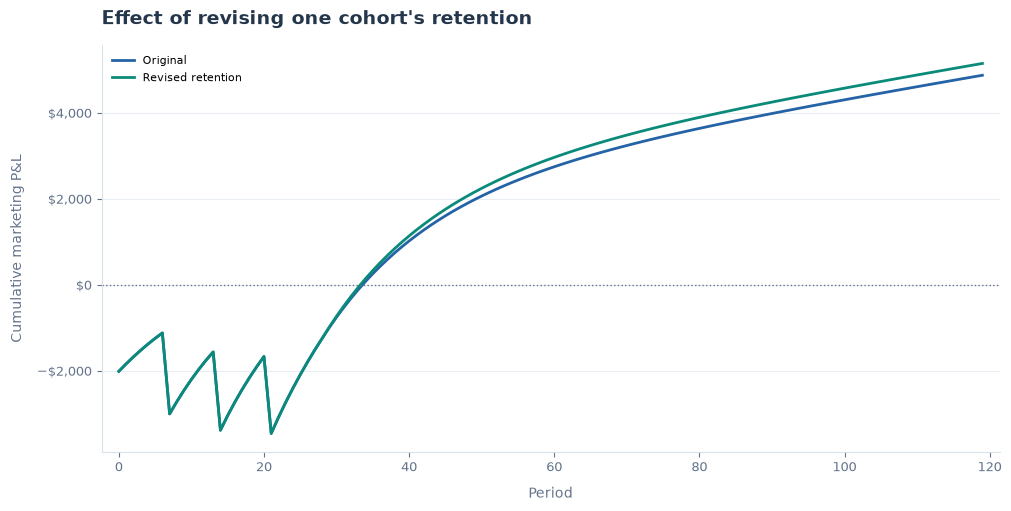

In [22]:
revision_chart = tg.viz.scenario_comparison(
    {"Original": result, "Revised retention": revised},
    title="Effect of revising one cohort's retention",
)
display(revision_chart.figure)

## 9. Timeline API: calendar dates and monthly checkpoints

The same sources can use daily datetime values instead of abstract integers. Convert acquisition dates, observation dates, spend dates, the cursor, and the horizon consistently; do not mix date types within a forecast.

Months are **calendar anniversaries of acquisition**, not 30-day approximations. A January 31 cohort reaches its first monthly boundary on February 29 in this example and its second on March 31. The point includes revenue through the day before the boundary. With integer periods, use an explicit `interval=30` instead of `"monthly"`.

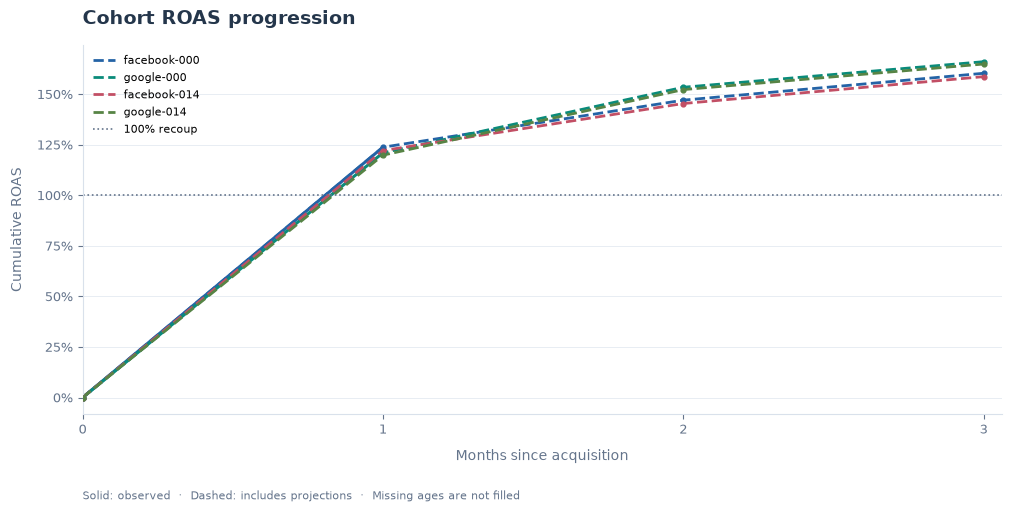

,interval_index,elapsed_days,period,cumulative_revenue,roas
0,0,0,2024-01-31,0.0000,0.0000
1,1,29,2024-02-28,"1,423.4520",1.2378
2,2,60,2024-03-30,"1,691.0900",1.4705
3,3,90,2024-04-29,"1,844.0012",1.6035


In [23]:
calendar_start = pd.Timestamp("2024-01-31")

def to_calendar(frame, column):
    converted = frame.copy()
    converted[column] = calendar_start + pd.to_timedelta(converted[column], unit="D")
    return converted


calendar_frames = tg.SourceFrames(
    cohorts=to_calendar(cohorts, "acquisition_period"),
    curves=curves.copy(),  # Curve ages remain integers.
    observations=to_calendar(observations, "period"),
    acquisition_spend=to_calendar(acquisition_spend, "period"),
)
calendar_result = tg.forecast(
    calendar_frames,
    as_of=calendar_start + pd.Timedelta(days=AS_OF),
    forecast_end=calendar_start + pd.Timedelta(days=FORECAST_END),
)
np.testing.assert_allclose(
    result.timeline()["marketing_pnl"],
    calendar_result.timeline()["marketing_pnl"],
)

monthly_chart = calendar_result.plot.cohort_progression(
    interval="monthly", cohorts=selected_cohorts
)
display(monthly_chart.figure)
display(monthly_chart.data.loc[
    monthly_chart.data["cohort_id"].eq("facebook-000"),
    ["interval_index", "elapsed_days", "period", "cumulative_revenue", "roas"],
])

# For abstract integer days, explicitly request fixed 30-day windows.
thirty_day_progression = result.cohort_progression(interval=30)
assert not thirty_day_progression.empty

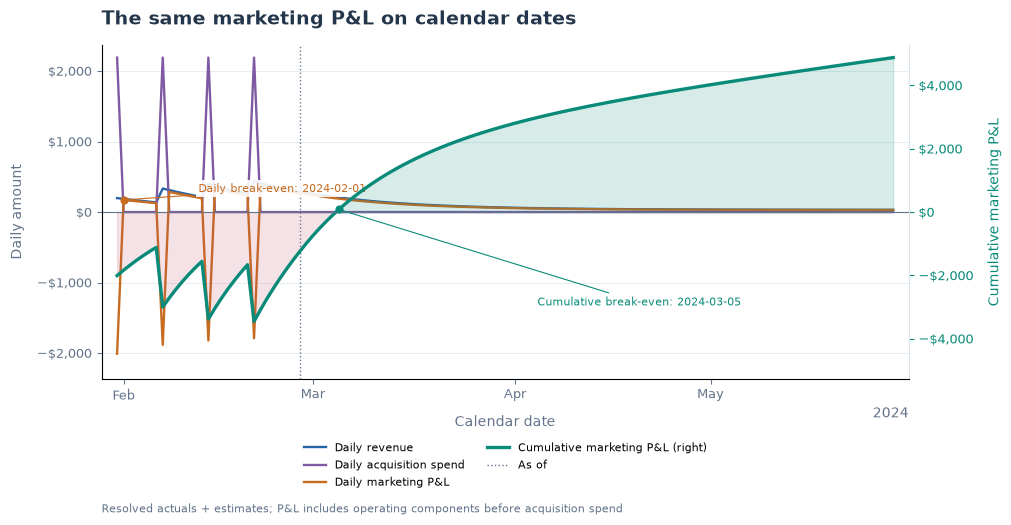

In [24]:
calendar_pnl_chart = calendar_result.plot.marketing_pnl(
    title="The same marketing P&L on calendar dates"
)
display(calendar_pnl_chart.figure)

## 10. Scenario comparison: `tg.viz.scenario_comparison`

A model can include future cohorts and their planned acquisition spend. Here we compare stopping acquisition after the initial four waves with continuing weekly through the horizon. We keep the original observations and economics identical.

Later cohorts have less time to contribute before the common horizon. This is a finite-horizon funding/profitability comparison, not a like-for-like estimate of each cohort's ultimate LTV.

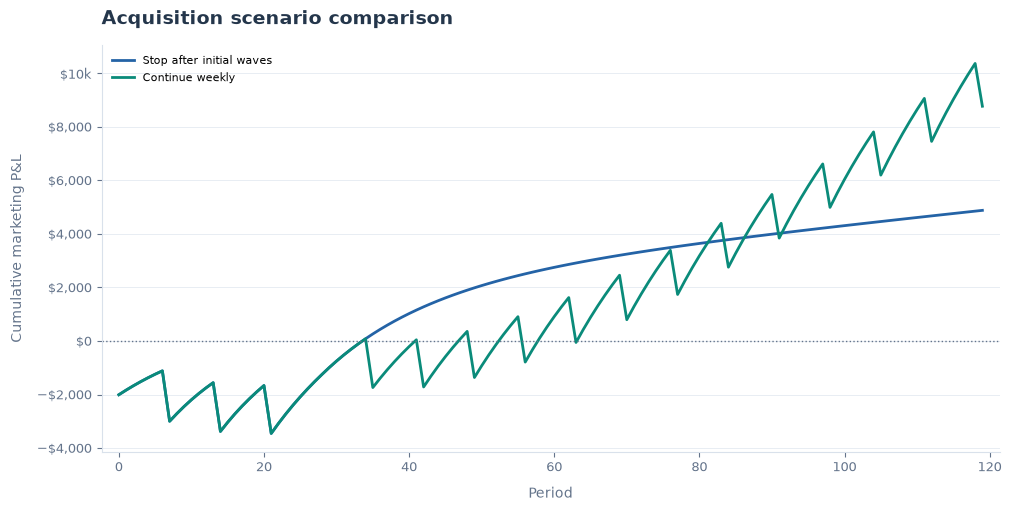

,,acquisition_spend,marketing_pnl,cash_at_risk
Stop after initial waves,0,"8,760.0000","4,878.3159","3,453.6491"
Continue weekly,0,"37,230.0000","8,766.8413","3,453.6491"


In [25]:
planned_cohorts, planned_spend = make_acquisitions(range(35, FORECAST_END + 1, 7))
ongoing = tg.forecast(
    pd.concat([cohorts, planned_cohorts], ignore_index=True),
    curves,
    observations=observations,
    acquisition_spend=pd.concat([acquisition_spend, planned_spend], ignore_index=True),
    as_of=AS_OF,
    forecast_end=FORECAST_END,
)
acquisition_chart = tg.viz.scenario_comparison(
    {"Stop after initial waves": result, "Continue weekly": ongoing}
)
display(acquisition_chart.figure)
display(pd.concat({
    "Stop after initial waves": result.metrics(),
    "Continue weekly": ongoing.metrics(),
})[["acquisition_spend", "marketing_pnl", "cash_at_risk"]])

### Put the main views on one figure

The dashboard composes six of the same chart functions; it is an ordinary Matplotlib figure, not a dashboard application. Cohort filters apply to cohort panels. Portfolio P&L, spend, and receivables panels still show the **entire** result.

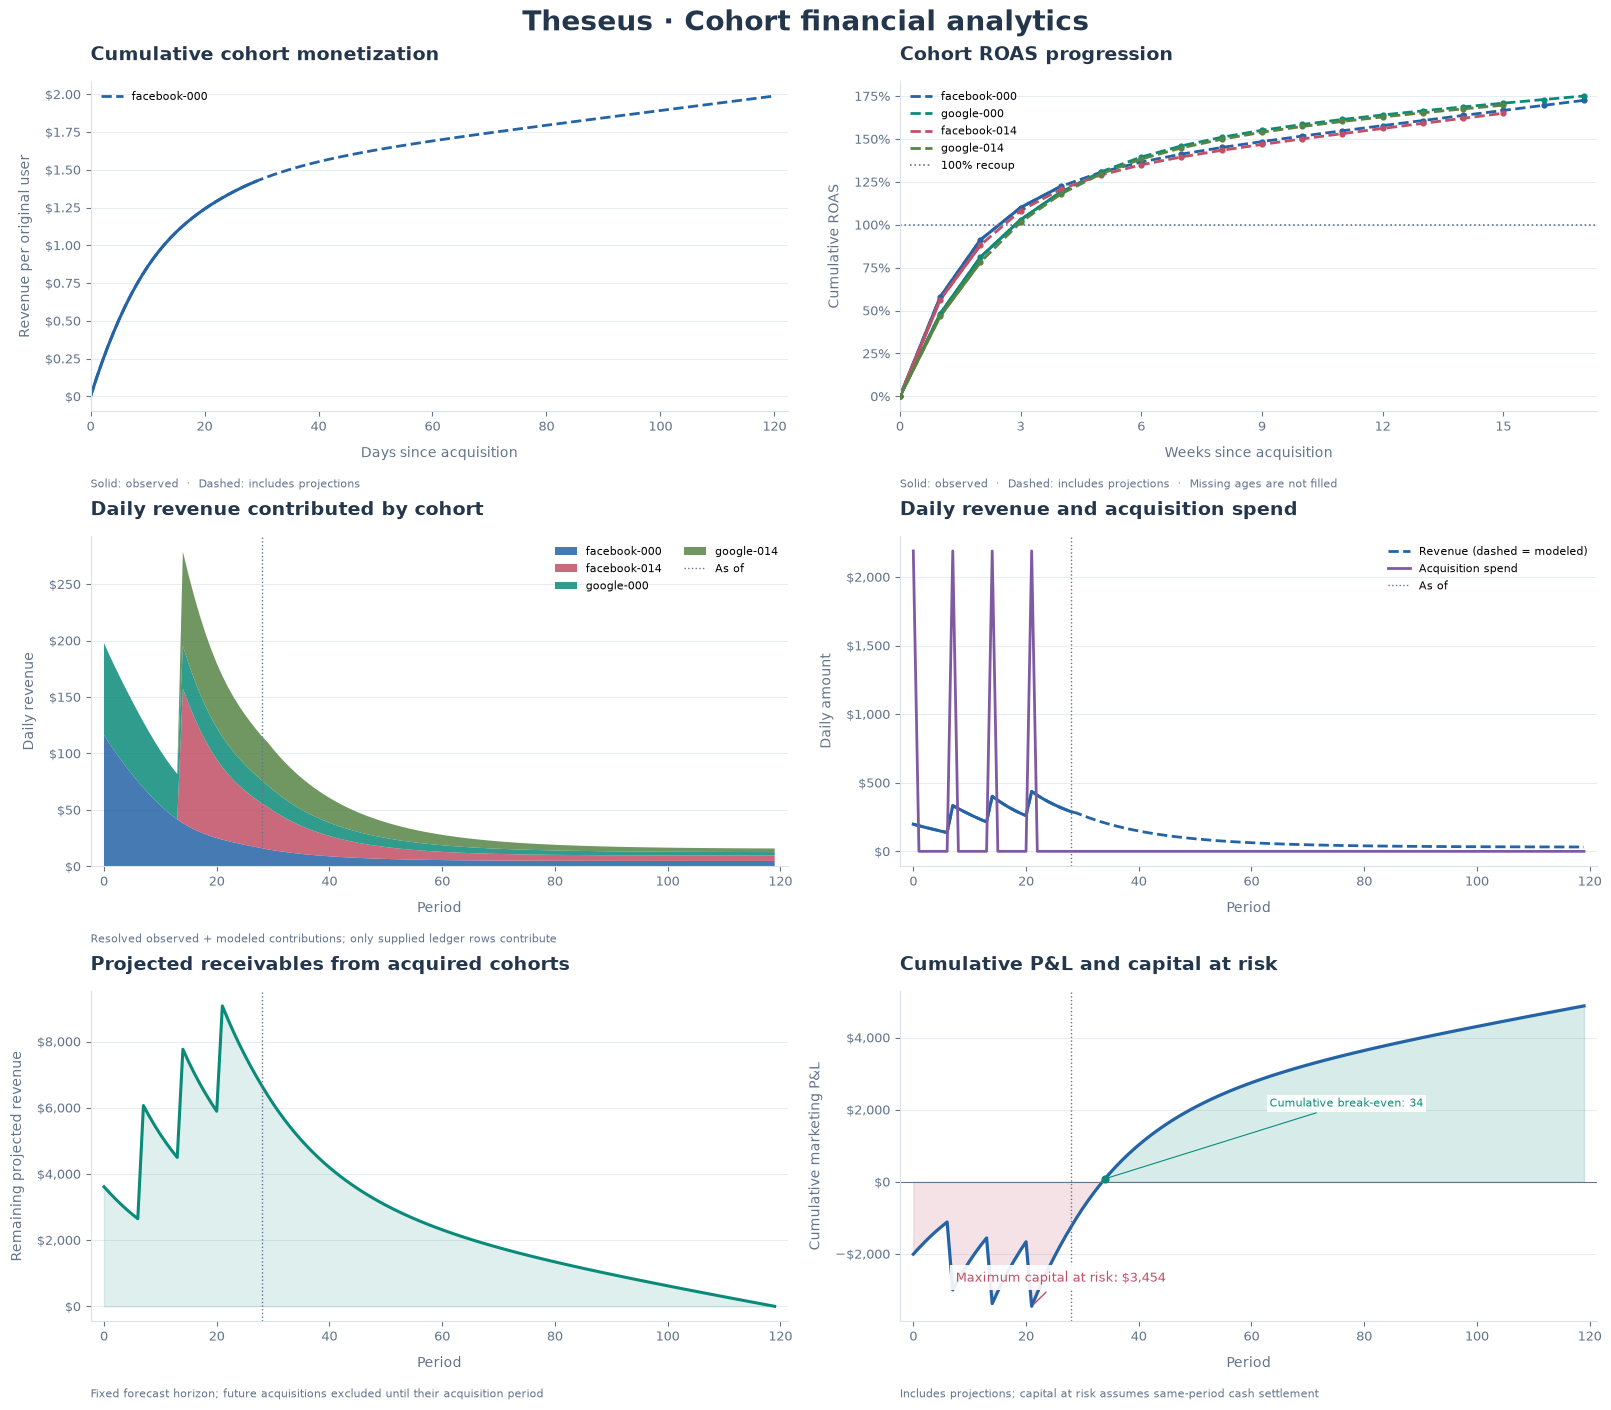

Underlying dashboard DataFrames: monetization, progression, cohort_revenue, daily_revenue, receivables, cumulative_pnl


In [26]:
dashboard_chart = result.plot.dashboard(
    cohorts=selected_cohorts, interval="weekly"
)
display(dashboard_chart.figure)
print("Underlying dashboard DataFrames:", ", ".join(dashboard_chart.tables))

## 11. Input adapters: CSV, XLSX, and databases

Adapters sit at the boundary. They materialize the same four DataFrames used above; they do not own storage or impose an application architecture.

These demo cells write under `examples/output/notebook/`, which is ignored by Git. CSV does not preserve datetime dtypes by itself: parse calendar columns explicitly when needed. XLSX readers consume stored values; Theseus does not calculate Excel formulas.

We round-trip the **source** frames and compare their forecast with the original. A result export is a report, not a source workbook or serialized incremental state.

In [27]:
output_dir = Path("examples/output/notebook")
output_dir.mkdir(parents=True, exist_ok=True)
csv_dir = output_dir / "source_csv"

tg.io.write_csv_directory(source_frames, csv_dir)
csv_frames = tg.io.read_csv_directory(csv_dir)
single_csv = tg.io.read_csv(csv_dir / "cohorts.csv")

# The interchangeable source abstraction exposes load() -> SourceFrames.
csv_source = tg.io.CsvSource(csv_dir)
csv_result = tg.forecast(
    tg.io.load_source(csv_source), as_of=AS_OF, forecast_end=FORECAST_END
)
assert_frame_equal(result.timeline(), csv_result.timeline(), check_dtype=False)
display(single_csv)
print("CSV round-trip preserves the financial timeline.")

,cohort_id,acquisition_period,population,curve_id,channel
0,facebook-000,0,1000,facebook,facebook
1,google-000,0,800,google,google
2,facebook-007,7,1000,facebook,facebook
3,google-007,7,800,google,google
4,facebook-014,14,1000,facebook,facebook
5,google-014,14,800,google,google
6,facebook-021,21,1000,facebook,facebook
7,google-021,21,800,google,google


CSV round-trip preserves the financial timeline.


In [28]:
template_path = output_dir / "source_template.xlsx"
tg.io.write_xlsx_template(template_path, include_examples=True)

source_workbook = output_dir / "source_data.xlsx"
with pd.ExcelWriter(source_workbook, engine="openpyxl") as writer:
    for frame_name, sheet_name in tg.io.DEFAULT_SHEETS.items():
        getattr(source_frames, frame_name).to_excel(
            writer, sheet_name=sheet_name, index=False
        )

xlsx_frames = tg.io.read_xlsx(source_workbook)
validated_frames = tg.io.validate_xlsx(source_workbook)
xlsx_source = tg.io.XlsxSource(source_workbook)
xlsx_result = tg.forecast(
    tg.io.load_source(xlsx_source), as_of=AS_OF, forecast_end=FORECAST_END
)
assert_frame_equal(result.timeline(), xlsx_result.timeline(), check_dtype=False)
assert len(validated_frames.cohorts) == len(cohorts)
print("XLSX round-trip preserves the financial timeline.")
print("Input workbook sheets:", ", ".join(tg.io.DEFAULT_SHEETS.values()))

XLSX round-trip preserves the financial timeline.
Input workbook sheets: Cohorts, Curves, Observations, Acquisition Spend


### Optional database boundary, not a database-backed engine

`DatabaseSource` accepts a **caller-owned connection** and caller-supplied queries. The forecast still consumes DataFrames. Use read-only queries and appropriate connection permissions in your integration; the adapter does not enforce a SQL sandbox.

This self-contained example seeds a disposable **in-memory SQLite database**, reads it, then closes it. It does not connect to or modify any existing database. Any custom object implementing `load() -> SourceFrames` can serve as a source without using SQL at all.

In [29]:
with closing(sqlite3.connect(":memory:")) as connection:
    # Demo setup is caller code, not a write performed by Theseus.
    for name in tg.io.DEFAULT_SHEETS:
        getattr(source_frames, name).to_sql(name, connection, index=False)

    database_source = tg.io.DatabaseSource(
        connection=connection,
        queries={
            "cohorts": "SELECT * FROM cohorts",
            "curves": "SELECT * FROM curves",
            "observations": "SELECT * FROM observations WHERE period <= :cursor",
            "acquisition_spend": "SELECT * FROM acquisition_spend",
        },
        params={"observations": {"cursor": AS_OF}},
    )
    database_frames = tg.io.load_source(database_source)

database_result = tg.forecast(
    database_frames, as_of=AS_OF, forecast_end=FORECAST_END
)
assert_frame_equal(result.timeline(), database_result.timeline(), check_dtype=False)
print("SQLite adapter produces the same DataFrame-based forecast.")

SQLite adapter produces the same DataFrame-based forecast.


## 12. Export and customization

Save a report workbook, a ledger CSV, chart-ready data, or the figure itself. PNG, SVG, and PDF use the same `Chart.save` method. You can also edit Matplotlib axes before exporting; no separate theme or application layer is required.

In [30]:
result.to_xlsx(output_dir / "financial_report.xlsx")
result.contributions.to_csv(output_dir / "contributions.csv", index=False)
weekly_progression_chart.data.to_csv(
    output_dir / "observed_weekly_roas.csv", index=False
)

weekly_progression_chart.ax.set_title("Observed weekly cohort ROAS")
weekly_progression_chart.save(output_dir / "observed_weekly_roas.png")
weekly_progression_chart.save(output_dir / "observed_weekly_roas.svg")
dashboard_chart.save(output_dir / "cohort_financials.pdf")

report_sheets = pd.ExcelFile(output_dir / "financial_report.xlsx")
with report_sheets:
    assert set(report_sheets.sheet_names) == {"Contributions", "Marketing PnL", "Metrics"}

display(pd.DataFrame([
    {"file": path.relative_to(output_dir).as_posix(),
     "size_kb": round(path.stat().st_size / 1024, 1)}
    for path in sorted(output_dir.rglob("*")) if path.is_file()
]))

,file,size_kb
0,cohort_financials.pdf,56.7000
1,contributions.csv,525.5000
2,financial_report.xlsx,286.4000
3,observed_weekly_roas.csv,1.3000
4,observed_weekly_roas.png,194.0000
5,observed_weekly_roas.svg,105.2000
6,source_csv/acquisition_spend.csv,0.2000
7,source_csv/cohorts.csv,0.3000
8,source_csv/curves.csv,58.5000
9,source_csv/observations.csv,27.9000


## 13. A few useful guardrails

Bad inputs should fail loudly. These examples deliberately exercise validation and catch the expected errors. They do not interrupt a Run All execution.

In [31]:
expected_errors = []

def expect_error(label, operation):
    try:
        operation()
    except tg.TheseusError as exc:
        expected_errors.append({"case": label, "message": str(exc)})
    else:
        raise AssertionError(f"{label} unexpectedly succeeded")


expect_error(
    "Calendar dates mixed with integer periods",
    lambda: tg.forecast(
        cohorts, curves, as_of=AS_OF, forecast_end=pd.Timestamp("2024-06-01")
    ),
)
expect_error(
    "Monthly checkpoints on abstract integer days",
    lambda: result.cohort_progression(interval="monthly"),
)
expect_error(
    "Advance feed contains the wrong day",
    lambda: result.advance(
        observations=next_observations.assign(period=next_period + 1)
    ),
)
display(pd.DataFrame(expected_errors))
assert len(expected_errors) == 3
print("All walkthrough checks passed.")

,case,message
0,Calendar dates mixed with integer periods,Periods must be either all integers or all cal...
1,Monthly checkpoints on abstract integer days,Calendar-month intervals require datetime peri...
2,Advance feed contains the wrong day,Every observations.period passed to advance mu...


All walkthrough checks passed.


## Where to go next

Change the channel economics or acquisition schedule, then restart and run all cells to compare the new outputs. For your own data, replace the four source DataFrames; the forecast and chart calls stay the same.

Keep these V1 boundaries in mind:

- Forecasting consumes explicit curves; it does not infer the process that generated your cohorts, fit retention automatically, or invent missing curve tails.
- `advance` moves one daily step and preserves prior observations. Use a broadcast for new assumptions and rebuild from corrected observations when restating actual data.
- Retention revisions affect per-active-user components. Direct per-original-user revenue curves are independent of retention unless you construct them otherwise.
- Ratios use cohort-specific spend and revenue; P&L additionally includes modeled/observed costs. All money inputs must use a consistent currency.
- Projections and receivables stop at the chosen horizon. Capital-at-risk figures assume same-period settlement.

### Continue into scenario planning

- [Game CFO: optimize growth and a $1MM bank-cash target](examples/notebooks/Game_CFO_Cash_Flow_Optimization.ipynb)
- [Subscription CFO: evaluate channel tests and a CTV halo](examples/notebooks/Subscription_CFO_Channel_Experiments.ipynb)
- [Subscription CMO: optimize campaign spend with Waterfall and Distributed budgeting](examples/notebooks/Subscription_CMO_Campaign_Optimization.ipynb)

See [README.md](README.md) for the schemas and API details, or [the visualization gallery script](examples/visualization_suite.py) for a standalone chart-export example.